# Assignment 2 - Part 1: HST Calibration Routine
------

## Objective

TODO

## Steps

TODO

In [ ]:
# Packages & import

from pathlib import Path
import matplotlib
from astropy.io import fits
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

import numpy as np

# Custom utils functions import
from Assignment_2.HST.hst_utils import (
    open_fits_file,
    load_calibration_files,
    normalize_image,
    transform_by,  # AUTHOR: Dr Andrew Kirwan
    plot_calibration_files,
    print_statistics,
    mask_invalid_data,
    photometry_tables,
    mask_statistics,
    remove_bias_level,
    remove_bias_image,
    plot_correction,
    remove_dark,
    correct_flatfield,
    filter_mad,
    get_sky,
    EXPTIME,
DPC,
    )

In [ ]:
import importlib
import Assignment_2.HST.hst_utils as hu
importlib.reload(hu)       # pick up any edits to the file since the kernel started

print([n for n in dir(hu) if not n.startswith("_")])

In [ ]:
import Assignment_2.HST.hst_utils as utils
importlib.reload(utils)

print([name for name in dir(utils) if not name.startswith("_")])

### 0. Import files
-----

In [ ]:
# Import the .fits files
calib_dir = Path("hst-calibration")
ubai2505m = load_calibration_files(calib_dir / "ubai2505m")
raw_header, raw_data = ubai2505m["raw"]

# Logging
print("File type | Data shape |  Data type")
for file_type, (header, data) in ubai2505m.items():
    print(f"{file_type:10s} {str(data.shape):16s} {data.dtype}")
    #print(raw_header)

**Visualization of the files**

In [ ]:
# def plot_calibration_files(files, chip=0):
#     """
#     Plot one chip of the raw and calibration images, two per row.
#     """
#     names = ["raw", "maskfile", "blevfile", "biasfile", "darkfile", "flatfile"]
#     fig, axes = plt.subplots(3, 2, figsize=(10, 15))
#     axes = axes.ravel()
#
#     for i in range(len(names)):
#         data = files[names[i]][1][chip]
#         # The mask only has the values 0, 2 and 256, so no log stretch
#         if names[i] == "maskfile":
#             image = transform_by("linear", data, pmin=0, pmax=100)
#         else:
#             image = transform_by("log", data, pmin=1, pmax=99)
#         im = axes[i].imshow(image, origin="lower", aspect="auto")
#         axes[i].set_title(f"{names[i]} (chip {chip})")
#         fig.colorbar(im, ax=axes[i])
#
#
#     fig.tight_layout()
#     plt.show()


plot_calibration_files(ubai2505m, chip=0)


### 1. Mask invalid data with `MASKFILE`
The mask indicates all bad pixels as follows:
 - 0 represents a valid pixels
 - 2 represents defective pixels
 - 256 represents 'questionable pixels'
-----

In [ ]:
# Secondary header will be required for photometric calibration
mask_header, mask_data = ubai2505m["maskfile"]

# Statistics on the number of valid, defective, and questionable pixels
print("Mask statistics")
for chip in range(mask_data.shape[0]):
    total = mask_data[chip].size
    valid = np.sum(mask_data[chip] == 0)
    defective = np.sum(mask_data[chip] == 2)
    questionable = np.sum(mask_data[chip] == 256)
    print(
        f"Chip {chip}: total = {total}, "
        f"valid = {valid} ({100 * valid / total:.2f}%), "
        f"defective = {defective} ({100 * defective / total:.2f}%), "
        f"questionable = {questionable} ({100 * questionable / total:.2f}%)"
    )

In [ ]:
stats = mask_statistics(ubai2505m)

In [ ]:
# Plot the maskfile on top of the rawfile, clearly highlighting the masked pixels.
# A second plot zooms on the area where there are some bad columns.
chip = 0
raw_image = transform_by("sqrt", raw_data[chip], pmin=1, pmax=99)

defective_y, defective_x = np.where(mask_data[chip] == 2)
questionable_y, questionable_x = np.where(mask_data[chip] == 256)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))
for ax in [ax1, ax2]:
    ax.imshow(raw_image, origin="lower", cmap="gray")
    ax.scatter(defective_x, defective_y, s=1, color="red", label="defective")
    ax.scatter(
        questionable_x,
        questionable_y,
        s=1,
        color="cyan",
        label="questionable",
    )

ax1.set_title(f"Raw image with masked pixels (chip {chip})")
ax1.legend(loc="lower left", markerscale=10, fontsize=16)

ax2.set_xlim(350, 500)
ax2.set_ylim(500, 650)
ax2.set_title("Zoom on the bad columns")
ax2.legend(loc="lower left", markerscale=10, fontsize=16)


fig.tight_layout()
plt.show()

**We observe:**
1. Some defective individuels pixels on the image
2. Some defective pixels on the same column, on top of each other
3. For those defective pixels on top of each other, all pixels on top of them in these columns are classified as 'questionable'

**Analysis:**

According to \url{https://www.stsci.edu/instrument-news/isr/wfpc2/9503/9503_1.html}, these effects are due to **charge traps**: single pixels that don't pass charge along properly. As CCDs are read columns by columns, all previous pixels in the column are considered as 'questionable'

**Decision:**

As the statistics show that less of 1% of the pixels are defective or questionable, and as recommended on the previous cited source, the chosen decision is to mask the defective and questionable pixels with Nan values. Note that the usage of nan-safe functions is thus required from now on.

Another, more complex approach would have been to interpolate these pixels, but we decided not to do so as it would create fake data into our measurements

In [ ]:
# # replace all the defective and questionable pixels by Nan in the raw_data
# def mask_invalid_data(raw_data, mask_data):
#     """
#     Return a float copy of raw_data where the defective (2) and
#     questionable (256) pixels of mask_data are set to NaN.
#     """
#     raw_data_masked = raw_data.astype(float)
#     raw_data_masked[(mask_data == 2) | (mask_data == 256)] = np.nan
#     return raw_data_masked


raw_data_masked = mask_invalid_data(raw_data, mask_data)
# Check: number of masked pixels per chip
print("Raw Data Masked:")
for chip in range(raw_data_masked.shape[0]):
    print(f"Chip {chip}: {np.sum(np.isnan(raw_data_masked[chip]))} pixels set to NaN")


### 2. Correct Analog-to-Digital conversion errors with `ATODFILE`
-----
**Not required**: the `raw.fits` files given are already ADC-corrected

### 3. Remove bias level with `BLEVFILE`
-----
The `BLEVFILE` countains the ias level values: DC offsets applied to ensure our values are always positive.

Because HST uses 12 bits for number representation, values are between 0- 4095 range. 

The bias level file uses the **overscan** region of each chip (pixels always covered) to calculate the padding required to ensure only positive numbers. For WFPC2, the overscan region is in columns 9-14 and rows 10-790 `data[9:790, 8:14]`.

Bias levels for even and odd rows are different: 
- `BIASODD`: columns 9, 11, 13 ; considering Python indexing: 8, 10, 12
- `BIASEVEN`: columns 8, 10, 12 ; Python indexing: 7, 9, 11

Bias level correction
1. Get the mean value of the odd/even overscan regions
2. Substract that from all odd/even columns of the image

In [ ]:
# def print_statistics(data, name="Data"):
#     """
#     Print the mean, median, standard deviation, min and max of each chip.
#     NaN-safe functions are used because the masked pixels are NaN.
#     """
#     print(f"{name} statistics: ")
#     for chip in range(data.shape[0]):
#         print(
#             f"Chip {chip}: mean = {np.nanmean(data[chip]):.2f}, "
#             f"median = {np.nanmedian(data[chip]):.2f}, "
#             f"std = {np.nanstd(data[chip]):.2f}, "
#             f"min = {np.nanmin(data[chip]):.2f}, "
#             f"max = {np.nanmax(data[chip]):.2f}"
#         )
#     print()


def remove_bias_level(raw_data_masked, blev_data):
    """
    Subtract the mean overscan level of the BLEVFILE from each chip.
    Even and odd columns are corrected with their own mean.
    """
    raw_data_blev_corrected = raw_data_masked.copy()

    for chip in range(raw_data_masked.shape[0]):
        # Divide the overscan in even and odd columns
        blev_overscan_even = blev_data[chip, :, 7:12:2]
        blev_overscan_odd = blev_data[chip, :, 8:13:2]

        # Get the mean values
        overscan_even_mean = np.mean(blev_overscan_even)
        overscan_odd_mean = np.mean(blev_overscan_odd)

        # Subtract
        for i in range(raw_data_masked.shape[2]):
            is_even_column = (i % 2 == 1)  # Don't forget python indexing
            if is_even_column:
                raw_data_blev_corrected[chip, :, i] -= overscan_even_mean
            else: # Odd column
                raw_data_blev_corrected[chip, :, i] -= overscan_odd_mean
    print()

    return raw_data_blev_corrected


# Get the blevfile
blev_header, blev_data = ubai2505m["blevfile"]
# Only the overscan columns are pixel data (column 0 and 1 are not)
print_statistics(blev_data[:, :, 7:12:2], name="Blev overscan even columns")
print_statistics(blev_data[:, :, 8:13:2], name="Blev overscan odd columns")

# Statistics before and after the bias correction
print_statistics(raw_data_masked, name="Masked data")
raw_data_blev_corrected = remove_bias_level(raw_data_masked, blev_data)
print_statistics(raw_data_blev_corrected, name="Bias corrected")

In [ ]:
def plot_correction(before, correction, after, titles, chip=0):
    """
    Plot one chip of the image before the correction, the correction
    that was subtracted and the image after the correction, side by side.
    The colour limits are the 1st and 99th percentiles of each image.
    """
    images = [before[chip], correction[chip], after[chip]]

    fig, axes = plt.subplots(1, 3, figsize=(20, 6))
    for i in range(3):
        vmin = np.nanpercentile(images[i], 1)
        vmax = np.nanpercentile(images[i], 99)
        im = axes[i].imshow(images[i], origin="lower", cmap="plasma", vmin=vmin, vmax=vmax)
        axes[i].set_title(f"{titles[i]} (chip {chip})")
        fig.colorbar(im, ax=axes[i], label="DN")

    fig.tight_layout()
    plt.show()


# The subtracted bias level is the difference between the two images
bias_level = raw_data_masked - raw_data_blev_corrected
plot_correction(
    raw_data_masked,
    raw_data_blev_corrected,
    bias_level,
    ["Masked data", "Bias level corrected", "Difference"],
)

### 4. Remove bias image with `BIASFILE`
-----
The `BIASFILE` is an image of the same shape as the raw science exposure which compensates for readout noise. We get it by just taking a short exposure with a closed shutted. 

It can simply be substracted from our bias level corrected image

In [ ]:
bias_header, bias_data = ubai2505m["biasfile"]

def remove_bias_image(raw_data_blev_corrected, bias_data):
    """
    Subtract the bias data image from the blev corrected image
    """
    # Simply substract one from the other
    raw_data_bias_corrected = raw_data_blev_corrected - bias_data
    return raw_data_bias_corrected

raw_data_bias_corrected = remove_bias_image(raw_data_blev_corrected, bias_data)

# Logging
print_statistics(raw_data_blev_corrected, name="Blev corrected")
print_statistics(bias_data, name="Bias image")
print_statistics(raw_data_bias_corrected, name="Bias corrected")

In [ ]:
plot_correction(
    raw_data_blev_corrected,
    bias_data,
    raw_data_bias_corrected,
    ["Bias level corrected", "Bias image", "Bias image corrected"],
)

### 5. Substract dark with `DARKFILE` 
-----
The `DARKFILE` is a closed-shutter image which accounts for thermal noise (dark current). The reference file was normalized to an exposure time of 1 second (see its `HISTORY`), so its values are in DN/s.

Thus, the darkfile image should be first multiplied by the dark time of the science image (`DARKTIME` = 700 s in the raw header), then substracted from the bias corrected image.

In [ ]:
def remove_dark(raw_data_bias_corrected, dark_data, dark_time):
    """
    Subtract the dark image, considering dark time time, from the bias corrected data
    """
    raw_data_dark_corrected = raw_data_bias_corrected - dark_data * dark_time
    return raw_data_dark_corrected

# Get the darkfile & exposure time
dark_header, dark_data = ubai2505m["darkfile"]
dark_time = raw_header["DARKTIME"]

raw_data_dark_corrected = remove_dark(raw_data_bias_corrected, dark_data, dark_time)

# Logging
print_statistics(raw_data_bias_corrected, name="Bias corrected")
print_statistics(dark_data * dark_time, name=f"Dark data * darktime({dark_time}s)")
print_statistics(raw_data_dark_corrected, name="Dark corrected")

In [ ]:
plot_correction(
    raw_data_bias_corrected,
    dark_data * dark_time,
    raw_data_dark_corrected,
    ["Bias corrected", f"Dark image x {dark_time:.0f} s", "Dark corrected"],
)

### 6. Flatfield correction with `FLATFILE`
-----

`FLATFILE` is an image taken with a uniform exposure that accounts for pixel sensitivity variations across the detector.
The WPFC2 pipeline delivers it as an inverse sensitivity.

Thus, it should be multiplied with the dark corrected image


In [ ]:
def correct_flatfield(raw_data_dark_corrected, flat_data):
    """
    Multiply the image by the flat_data (inverse sensitivity)
    """
    raw_data_flat_corrected = raw_data_dark_corrected * flat_data
    return raw_data_flat_corrected

# Get the flatfile
flat_header, flat_data = ubai2505m["flatfile"]

raw_data_flat_corrected = correct_flatfield(raw_data_dark_corrected, flat_data)

# Logging
print_statistics(raw_data_bias_corrected, name="Dark corrected")
print_statistics(flat_data, name="Flatfield data")
print_statistics(raw_data_dark_corrected, name="Flatfield corrected")

In [ ]:
plot_correction(
    raw_data_dark_corrected,
    flat_data,
    raw_data_flat_corrected,
    ["Dark corrected", "Flatfield image", "Flatfield corrected"],
)

# Total Calibration

In [654]:
# thresh = 3
# sky = np.zeros(raw_data_flat_corrected.shape[0])
#
# for chip in range(raw_data_flat_corrected.shape[0]):
#     data = raw_data_flat_corrected[chip]
#
#     # MAD-based robust sigma (NaN-safe)
#     median = np.nanmedian(data)
#     mad = np.nanmedian(np.abs(data - median))
#     robust_std = 1.4826 * mad
#
#     # Keep pixels that are not NaN and not more than thresh robust sigmas above the median
#     keep = np.isfinite(data) & ((data - median) / robust_std <= thresh)
#
#     # Sky = median of the clipped sample
#     sky[chip] = np.median(data[keep])
#
# # Subtract the sky from the flatfield corrected data
# sky_corrected = raw_data_flat_corrected - sky[:, None, None]

In [674]:
from astropy.visualization import ImageNormalize, ZScaleInterval
from astropy.stats import sigma_clipped_stats

def subtract_sky(data, sigma=3.0, maxiters=5):
    """
    Subtracts the sky background from each chip.

    Parameters
    ----------
    data: numpy.ndarray
        The calibrated image data, with one chip per first axis.
    sigma: float
        The number of standard deviations from the median beyond which pixels (e.g. stars) are rejected. By default it is set to 3.0.
    maxiters: int
        The maximum number of clipping iterations. By default it is set to 5.

    Returns
    -------
    corrected: numpy.ndarray
        The data with the sky level subtracted from each chip.
    sky: numpy.ndarray
        The sky level of each chip: the median of the pixels left after clipping.
    sky_noise: numpy.ndarray
        The noise of the sky in each chip: the standard deviation of the pixels left after clipping.
        The standard deviation is used instead of MAD_STD because on the low-signal chips more than half
        the pixels share the same raw count, which makes the MAD collapse to zero and clip away half the sky.
    """
    sky = np.empty(data.shape[0])
    sky_noise = np.empty(data.shape[0])

    for chip in range(data.shape[0]):
        values = data[chip][np.isfinite(data[chip])]
        _, sky[chip], sky_noise[chip] = sigma_clipped_stats(values, sigma=sigma, maxiters=maxiters,
                                                            cenfunc='median', stdfunc='std')
    return data - sky[:, np.newaxis, np.newaxis], sky, sky_noise

sky_corrected, sky, sky_noise = subtract_sky(raw_data_flat_corrected)

print_statistics(sky_corrected, name="Sky subtracted")

------------------------ 
Sky subtracted statistics: 
Chip 0: mean = 1.59, median = 0.02, std = 41.07, min = -334.74, max = 10970.56
Chip 1: mean = 2.38, median = -0.00, std = 376.98, min = -642.85, max = 264339.43
Chip 2: mean = 3.23, median = 0.02, std = 148.39, min = -1655.19, max = 40456.71
Chip 3: mean = 4.30, median = 0.01, std = 172.98, min = -572.06, max = 44190.58



In [ ]:
# calib_dir = Path("hst-calibration")
# ubai2505m = load_calibration_files(calib_dir / "ubai2505m")
#
# exposure = ubai2505m
#
# raw_header, raw_data = exposure["raw"]
# mask_header, mask_data = exposure["maskfile"]
# blev_header, blev_data = exposure["blevfile"]
# bias_header, bias_data = exposure["biasfile"]
#
# # Get the darkfile & exposure time
# dark_header, dark_data = exposure["darkfile"]
# dark_time = raw_header["DARKTIME"]
#
# # Get the flatfile
# flat_header, flat_data = exposure["flatfile"]
#
# raw_data_masked = mask_invalid_data(raw_data, mask_data)
# stats = mask_statistics(exposure)
#
# raw_data_blev_corrected = remove_bias_level(raw_data_masked, blev_data)
#
# # The subtracted bias level is the difference between the two images
# bias_level = raw_data_masked - raw_data_blev_corrected
# raw_data_bias_corrected = remove_bias_image(raw_data_blev_corrected, bias_data)
#
# raw_data_dark_corrected = remove_dark(raw_data_bias_corrected, dark_data, dark_time)
#
# raw_data_flat_corrected = correct_flatfield(raw_data_dark_corrected, flat_data)
#
#
# print("------------------------ ")
# print("Raw Data Masked:")
# for chip in range(raw_data_masked.shape[0]):
#     print(f"Chip {chip}: {np.sum(np.isnan(raw_data_masked[chip]))} pixels set to NaN")
#
# # Only the overscan columns are pixel data (column 0 and 1 are not)
# print("\n------------------------ ")
# print_statistics(blev_data[:, :, 7:12:2], name="Blev overscan even columns")
# print("------------------------ ")
# print_statistics(blev_data[:, :, 8:13:2], name="Blev overscan odd columns")
#
# # Statistics before and after the bias correction
# print("------------------------ " )
# print_statistics(raw_data_masked, name="Masked data")
# raw_data_blev_corrected = remove_bias_level(raw_data_masked, blev_data)
# print("------------------------ " )
# print_statistics(raw_data_blev_corrected, name="Bias corrected")
#
# # Logging
# print("------------------------ " )
# print_statistics(raw_data_bias_corrected, name="Bias corrected")
# print("------------------------ " )
# print_statistics(dark_data * dark_time, name=f"Dark data * darktime({dark_time}s)")
# print("------------------------ " )
# print_statistics(raw_data_dark_corrected, name="Dark corrected")
#
# # Logging
# print("------------------------ " )
# print_statistics(raw_data_dark_corrected, name="Dark corrected")
# print("------------------------ " )
# print_statistics(flat_data, name="Flatfield data")
# print("------------------------ " )
# print_statistics(raw_data_flat_corrected, name="Flatfield corrected")
#
# # Correction Plots
#
# plot_correction(
#     raw_data_masked,
#     raw_data_blev_corrected,
#     bias_level,
#     ["Masked data", "Bias level corrected", "Difference"],
# )
#
# plot_correction(
# raw_data_bias_corrected,
# dark_data * dark_time,
# raw_data_dark_corrected,
# ["Bias corrected", f"Dark image x {dark_time:.0f} s", "Dark corrected"],
# )
#
# plot_correction(
# raw_data_dark_corrected,
# flat_data,
# raw_data_flat_corrected,
# ["Dark corrected", "Flatfield image", "Flatfield corrected"],
# )

### 7. Shading removing with `SHADFILE`
-----

Not required because the exposure time is not very short. 


### 8. Photometry calibration with `PHOTTAB`
-----

`PHOTTAB` is a throughput table generated by the pipeline from the HST component throughput tables. It contains the `PHOTFLAM`, `PHOTZPT` and `ZP_CORR` keys recquired for the photometry calibration.

**Strong assumtion**: `PHOTTAB` is not provided in the hst-calibration files or in the raw data. Thus, the `PHOTFLAM`, `PHOTZPT` and `ZP_CORR` keys are taken directly from the science-ready image.

Reminder from HST workshop 2:
| Keyword    | Description                                    |
|:-----------|:-----------------------------------------------|
| `PHOTFLAM` | Inverse sensitivity                            |
| `PHOTZPT`  | Zero point magnitude                           |
| `ZP_CORR`  | Delta magnitude correction for contamination   |

Calibration steps: 

1. Convert the image to a ***spectral flux density*** [# photons /(s *unit energy* Area)]
    - Divide the number of photons by the exposure time to get #photons/s.
    - Multiply the result by the Inverse sentivity (`PHOTFLAM`) to obtain $F_\lambda$
2. Compute the apparent and absolute magnitude (formulas from the Course manual):
    - *Apparent magnitude*
        $$
        m_{app} = -2.5 \times \log F_\lambda + ZPP
        $$
        Where $ZPP$ is the Zero-Point Magnitude (`PHOTZPT`)

    - *Absolute magnitude*
        $$
        M_{abs} = m_{app} + 5 - 5 \log(d_{pc})
        $$
        Where $\log(d_{pc})$ is the distance to the star in parsecs.
        **Assumtion**: the given image shows the **NGC1261** cluster, at a distance of $16.4pc$

    
3. Compute the aperture photometry using example stars? **Unspecified**


# Calibrating own files

# Remove Sky



In [ ]:
# raw_data_sky_corrected, sky, sky_image = correct_sky(raw_data_flat_corrected)
#
#
# print_statistics(raw_data_sky_corrected, name="Sky corrected")

In [ ]:
# def normalise_plot(image, title, chip=0):
#
#     fig, ax = plt.subplots(figsize=(10, 6))
#     for i in range(3):
#         vmin = np.nanpercentile(image, 1)
#         vmax = np.nanpercentile(image, 99)
#         im = ax.imshow(image, origin="lower", cmap="plasma", vmin=vmin, vmax=vmax)
#         ax.set_title(f"{title} (chip {chip})")
#         fig.colorbar(im, ax=ax, label="DN")
#
#     fig.tight_layout()
#     plt.show()

In [ ]:
# sky = get_sky(raw_data_flat_corrected)
# for chip in range(raw_data_flat_corrected.shape[0]):
#         raw_data_flat_corrected[chip] -= sky[chip]



In [676]:
# def spectral_flux(data):
#     counts_per_sec = data / EXPTIME
#     flux = counts_per_sec * photometry_tables["PHOTFLAM"]
#     return flux
flux = spectral_flux(sky_corrected)

In [677]:
def get_appmag(flux):
    """
    Converts the flux to the apparent magnitude
    """
    flux = np.asarray(flux, dtype=float)
    app_mags = np.full_like(flux, np.nan)
    good = np.isfinite(flux) & (flux > 0)
    app_mags[good] = -2.5 * np.log10(flux[good]) + photometry_tables["PHOTZPT"]
    return app_mags

In [678]:
def get_abs_mag(dpc, app_mag):
    """
    convert an apparent magnitude to absolute magnitude
    given a distance in parsec (pc)
    """
    return app_mag + 5 - 5 * np.log10(dpc)

In [679]:
app_mags = get_appmag(flux)
abs_mags = get_abs_mag(16.4e3, app_mags)

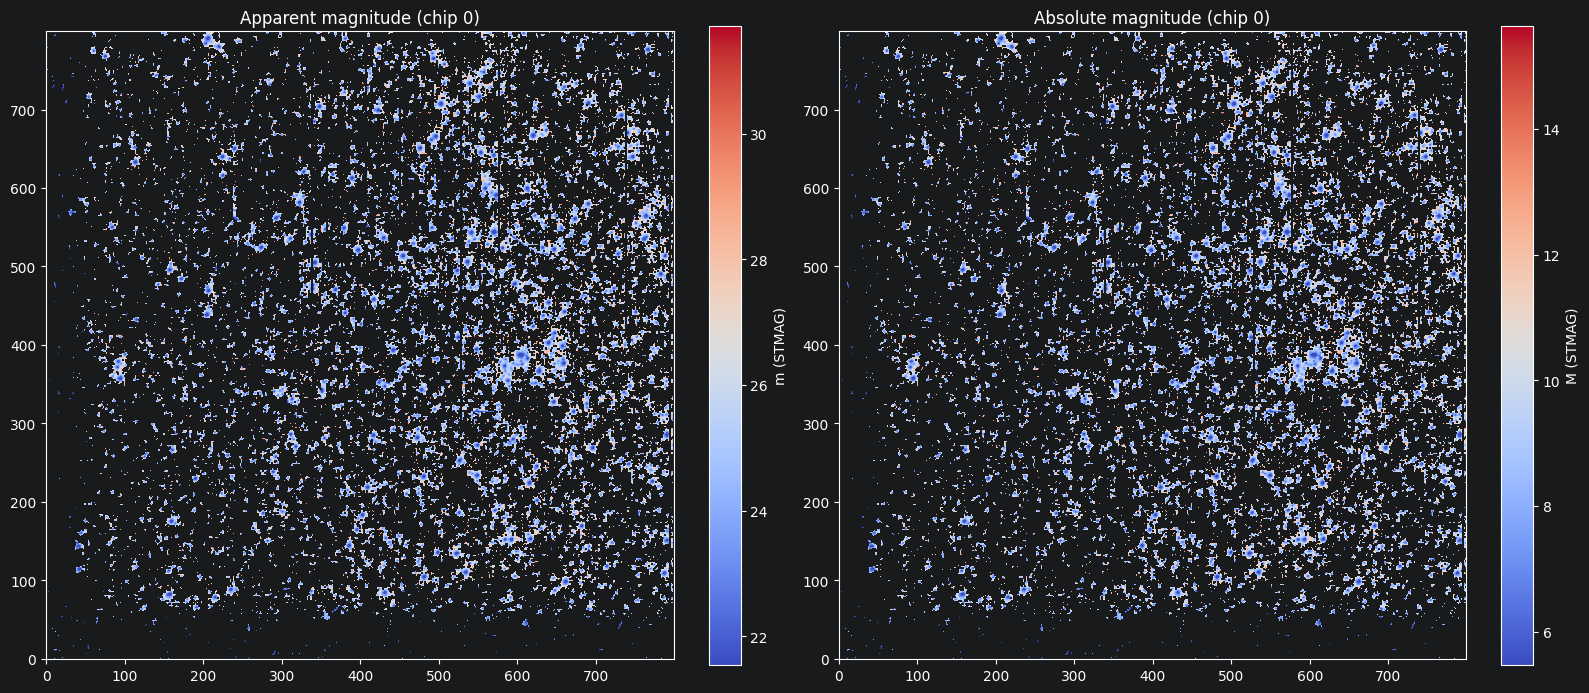

In [680]:
def plot_mags_side_by_side(app_mags, abs_mags, chip=0):
    fig, axes = plt.subplots(1, 2, figsize=(16, 7), tight_layout=True)

    for ax, mag, title, label in zip(
        axes,
        (app_mags, abs_mags),
        ("Apparent magnitude", "Absolute magnitude"),
        ("m (STMAG)", "M (STMAG)"),
    ):
        m = np.asarray(mag, dtype=float)
        if m.ndim == 3:
            m = m[chip]                              # (4, 800, 800) -> (800, 800)
        vmin, vmax = np.nanpercentile(m, [1, 99])
        im = ax.imshow(m, origin="lower", cmap="coolwarm", vmin=vmin, vmax=vmax)
        ax.set_title(f"{title} (chip {chip})")
        fig.colorbar(im, ax=ax, fraction=0.046, label=label)

    plt.show()

plt.close('all')
plot_mags_side_by_side(app_mags, abs_mags, chip=0)

In [681]:
print("Median Flux:", np.nanmedian(flux), " Highest Apparent Mag:", np.nanmin(app_mags))

Median Flux: 2.2006608260563218e-21  Highest Apparent Mag: 12.338767513281951


In [682]:
def calibrated_magnitudes(corrected_data, dpc):
    flux = spectral_flux(corrected_data)
    app_mag = get_appmag(flux)
    abs_mag = get_abs_mag(dpc, app_mags)

    return flux, app_mag, abs_mag

In [683]:
def aligned_magnitudes(data_file, dpc=hu.DPC, exptime=EXPTIME, counts_per_second=False):
    """
    Load an aligned FITS file and return (flux, apparent_mag, absolute_mag).

    counts_per_second: set True if BUNIT says the data are already rates,
                       so the exposure-time division is skipped.
    """
    with fits.open(data_file) as hdul:
        data = hdul[1].data.astype(float)
        bunit = hdul[1].header.get("BUNIT", hdul[0].header.get("BUNIT", "unknown"))

    rate = data if counts_per_second else data / exptime
    flux = rate * photometry_tables["PHOTFLAM"]          # erg / s / cm^2 / Angstrom

    app_mag = get_appmag(flux)                           # NaN where flux <= 0
    abs_mag = get_abs_mag(dpc, app_mag)

    return flux, app_mag, abs_mag


diff (mine - ref): mean +1.4541, median +0.9679, std 1.3119, robust std 1.2154


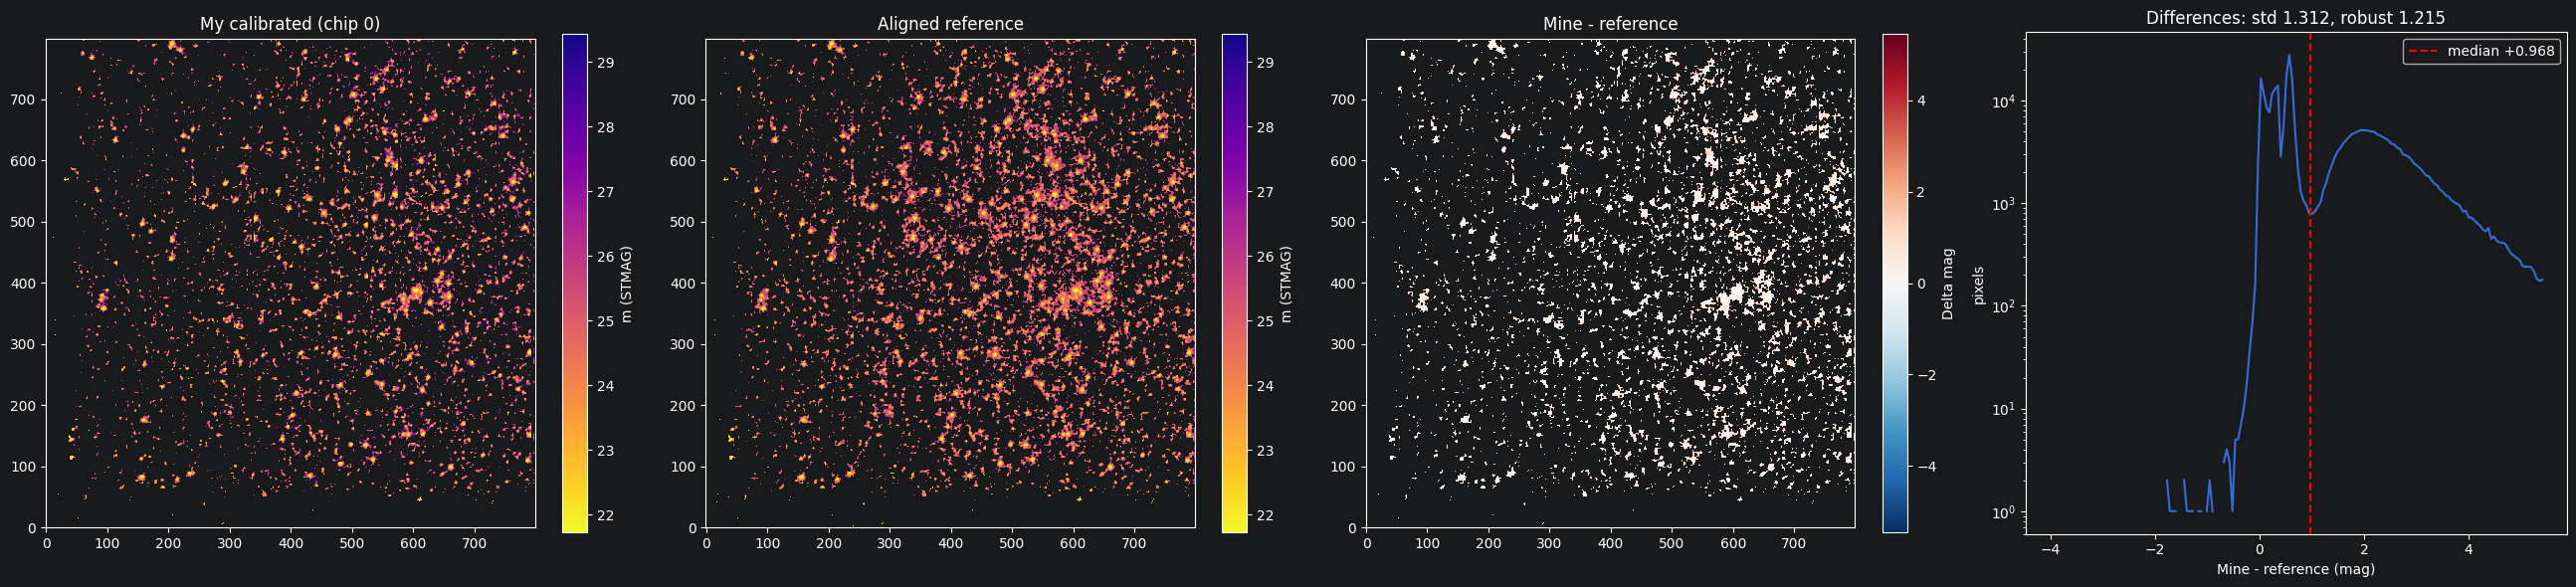

In [685]:
def compare_mags(calibrated, aligned, chip=0, mag_index=1, label="m (STMAG)"):
    """
    Compare magnitudes from my calibration with those from the aligned file.

    calibrated, aligned : tuples (flux, app_mag, abs_mag)
    chip      : chip of the (4, rows, cols) calibrated array that matches the aligned image
    mag_index : 1 = apparent, 2 = absolute (differences are identical)

    Returns (fig, stats); stats["diff_image"] is mine - reference.
    """
    mine = np.asarray(calibrated[mag_index], dtype=float)
    ref = np.asarray(aligned[mag_index], dtype=float)
    if mine.ndim == 3:
        mine = mine[chip]

    both = np.isfinite(mine) & np.isfinite(ref)

    diff = np.full_like(mine, np.nan)
    diff[both] = mine[both] - ref[both]
    d = diff[both]

    stats = {
        "mean": float(d.mean()),
        "median": float(np.median(d)),
        "std": float(d.std()),
        "robust_std": float(1.4826 * np.median(np.abs(d - np.median(d)))),
        "diff_image": diff,
    }

    print(f"diff (mine - ref): mean {stats['mean']:+.4f}, median {stats['median']:+.4f}, "
          f"std {stats['std']:.4f}, robust std {stats['robust_std']:.4f}")

    fig, axes = plt.subplots(1, 4, figsize=(26, 6), tight_layout=True)

    vmin, vmax = np.nanpercentile(ref, [1, 99])
    for ax, img, title in zip(axes[:2], (mine, ref),
                              (f"My calibrated (chip {chip})", "Aligned reference")):
        im = ax.imshow(img, origin="lower", cmap="plasma_r", vmin=vmin, vmax=vmax)
        ax.set_title(title)
        fig.colorbar(im, ax=ax, fraction=0.046, label=label)

    lim = np.nanpercentile(np.abs(d), 99)
    im = axes[2].imshow(diff, origin="lower", cmap="RdBu_r", vmin=-lim, vmax=lim)
    axes[2].set_title("Mine - reference")
    fig.colorbar(im, ax=axes[2], fraction=0.046, label="Delta mag")

    h, e = np.histogram(d, bins=np.linspace(-lim, lim, 201))
    axes[3].plot(0.5 * (e[:-1] + e[1:]), np.where(h > 0, h, np.nan))
    axes[3].axvline(stats["median"], color="r", ls="--", label=f"median {stats['median']:+.3f}")
    axes[3].set_yscale("log")
    axes[3].set_xlabel("Mine - reference (mag)")
    axes[3].set_ylabel("pixels")
    axes[3].set_title(f"Differences: std {stats['std']:.3f}, robust {stats['robust_std']:.3f}")
    axes[3].legend()

    return fig, stats

data_file = Path("hst-processed") / "science-ready" / "F336W" / "ubai2505m_c0m_aligned.fits"

cal = calibrated_magnitudes(sky_corrected, DPC)
ali = aligned_magnitudes(data_file)

fig, diffs = compare_mags(cal, ali, chip=0)
plt.show()
                     # the Delta-mag array

In [ ]:
# from astropy.visualization import ImageNormalize, ZScaleInterval
# from astropy.stats import sigma_clipped_stats
#
# def subtract_sky(data, sigma=3.0, maxiters=5):
#     """
#     Subtracts the sky background from each chip.
#
#     Parameters
#     ----------
#     data: numpy.ndarray
#         The calibrated image data, with one chip per first axis.
#     sigma: float
#         The number of standard deviations from the median beyond which pixels (e.g. stars) are rejected. By default it is set to 3.0.
#     maxiters: int
#         The maximum number of clipping iterations. By default it is set to 5.
#
#     Returns
#     -------
#     corrected: numpy.ndarray
#         The data with the sky level subtracted from each chip.
#     sky: numpy.ndarray
#         The sky level of each chip: the median of the pixels left after clipping.
#     sky_noise: numpy.ndarray
#         The noise of the sky in each chip: the standard deviation estimated with MAD_STD.
#     """
#     sky = np.empty(data.shape[0])
#     sky_noise = np.empty(data.shape[0])
#
#     for chip in range(data.shape[0]):
#         values = data[chip][np.isfinite(data[chip])]
#         _, sky[chip], sky_noise[chip] = sigma_clipped_stats(values, sigma=sigma, maxiters=maxiters,
#                                                             cenfunc='median', stdfunc='mad_std')
#
#     return data - sky[:, np.newaxis, np.newaxis], sky, sky_noise
#
# sky_subtracted, sky, sky_noise = subtract_sky(raw_data_flat_corrected)
# for chip, (level, noise) in enumerate(zip(sky, sky_noise)):
#     print(f"chip {chip} (DETECTOR {chip + 1}): sky {level:.4f} DN, MAD_STD {noise:.4f} DN, "
#           f"median after subtraction {np.nanmedian(sky_subtracted[chip]):.4f} DN")
#
# print("NaN before:", np.sum(np.isnan(raw_data_flat_corrected)), " after:", np.sum(np.isnan(sky_subtracted)))


# Comparing with Science-Ready files

In [686]:
data_file = Path("hst-processed") / "science-ready" / "F336W" / "ubai2505m_c0m_aligned.fits"
print(data_file.resolve(), data_file.exists())     # confirm before opening

with fits.open(data_file) as hdul:
    aligned = hdul[1].data.astype(float)

/Users/palakshi/Documents/GitHub/SDL-Python-Assignment/Assignment_2/HST/hst-processed/science-ready/F336W/ubai2505m_c0m_aligned.fits True


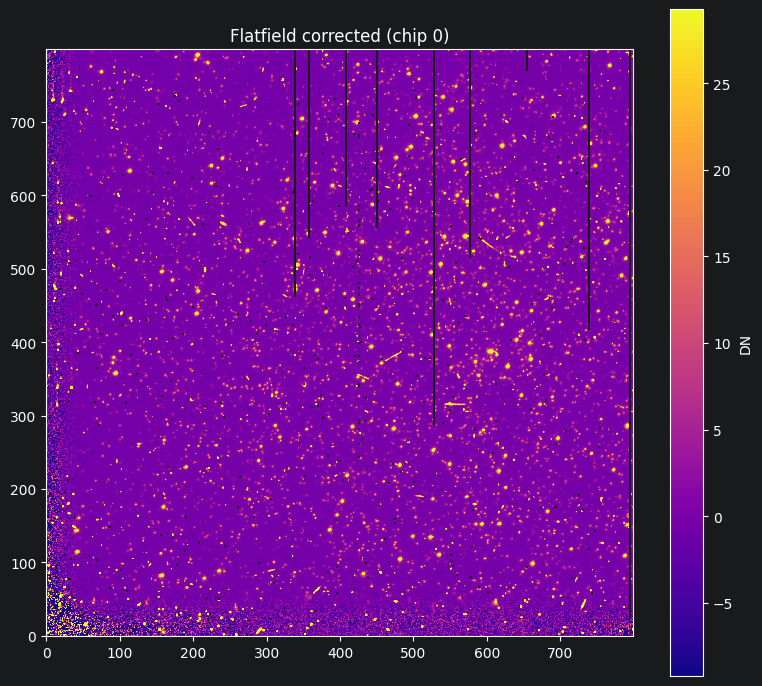

In [687]:
def plot_chip(image, chip=0, title="Image", label="DN"):
    """
    Plot one chip of a (4, rows, cols) array, or a single 2D image.
    Colour limits are the 1st and 99th percentiles.
    """
    image = np.asarray(image, dtype=float)
    if image.ndim == 3:
        image = image[chip]                      # (4, 800, 800) -> (800, 800)

    vmin, vmax = np.nanpercentile(image, [1, 99])

    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(image, origin="lower", cmap="plasma", vmin=vmin, vmax=vmax)
    ax.set_title(f"{title} (chip {chip})")
    fig.colorbar(im, ax=ax, label=label)
    fig.tight_layout()
    return fig

fig = plot_chip(sky_corrected, chip=0, title="Flatfield corrected")

In [688]:
def compare_to_reference(mine_all, ref, chip):
    mine = mine_all[chip]
    valid = np.isfinite(mine) & np.isfinite(ref)
    diff = mine - ref

    fig, axes = plt.subplots(2, 3, figsize=(20, 12), tight_layout=True)

    # row 1: images on a shared colour scale (from the reference)
    vmin, vmax = np.nanpercentile(ref, [1, 99])
    for ax, img, title in zip(axes[0, :2], (mine, ref),
                              (f"My calibration (chip {chip})", "HST reference (aligned)")):
        im = ax.imshow(img, origin="lower", cmap="plasma", vmin=vmin, vmax=vmax)
        ax.set_title(title)
        fig.colorbar(im, ax=ax, fraction=0.046, label="DN")

    # difference map
    lim = np.nanpercentile(np.abs(diff[valid]), 99)
    im = axes[0, 2].imshow(diff, origin="lower", cmap="RdBu_r", vmin=-lim, vmax=lim)
    axes[0, 2].set_title("Mine - reference")
    fig.colorbar(im, ax=axes[0, 2], fraction=0.046, label="DN")

    # row 2, panel 1: pixel-by-pixel 2D histogram with the 1:1 line
    lo, hi = np.nanpercentile(ref[valid], [0.5, 99.5])
    axes[1, 0].hist2d(ref[valid], mine[valid], bins=300,
                      range=[[lo, hi], [lo, hi]],
                      norm=plt.matplotlib.colors.LogNorm())
    axes[1, 0].plot([lo, hi], [lo, hi], "r--", label="1:1")
    axes[1, 0].set_xlabel("Reference (DN)")
    axes[1, 0].set_ylabel("Mine (DN)")
    axes[1, 0].set_title("Pixel-by-pixel")
    axes[1, 0].legend()

    # row 2, panel 2: value distributions as lines
    bins = np.linspace(lo, hi, 201)
    centres = 0.5 * (bins[:-1] + bins[1:])
    h_ref, _ = np.histogram(ref[valid], bins=bins)
    h_mine, _ = np.histogram(mine[valid], bins=bins)

    axes[1, 1].plot(centres, np.where(h_ref > 0, h_ref, np.nan), label="reference")
    axes[1, 1].plot(centres, np.where(h_mine > 0, h_mine, np.nan), label="mine", alpha=0.8)
    axes[1, 1].set_yscale("log")
    axes[1, 1].set_xlabel("DN")
    axes[1, 1].set_ylabel("pixels")
    axes[1, 1].legend()
    axes[1, 1].set_title("Value distributions")

    # row 2, panel 3: histogram of differences
    d = diff[valid]
    axes[1, 2].hist(d, bins=200, range=(-lim, lim))
    axes[1, 2].set_yscale("log")
    axes[1, 2].set_xlabel("Mine - reference (DN)")
    axes[1, 2].set_title(f"Differences: mean {d.mean():.2f}, std {d.std():.2f}")

    print(f"correlation: {np.corrcoef(mine[valid], ref[valid])[0, 1]:.4f}")
    print(f"mean diff {d.mean():.3f}, median diff {np.median(d):.3f}, std {d.std():.3f}")
    with np.errstate(divide="ignore", invalid="ignore"):
        ratio = mine[valid] / ref[valid]
    print(f"median ratio mine/ref: {np.nanmedian(ratio[np.isfinite(ratio)]):.3f}")
    return fig

correlation: 1.0000
mean diff -0.719, median diff -0.709, std 0.252
median ratio mine/ref: 0.713


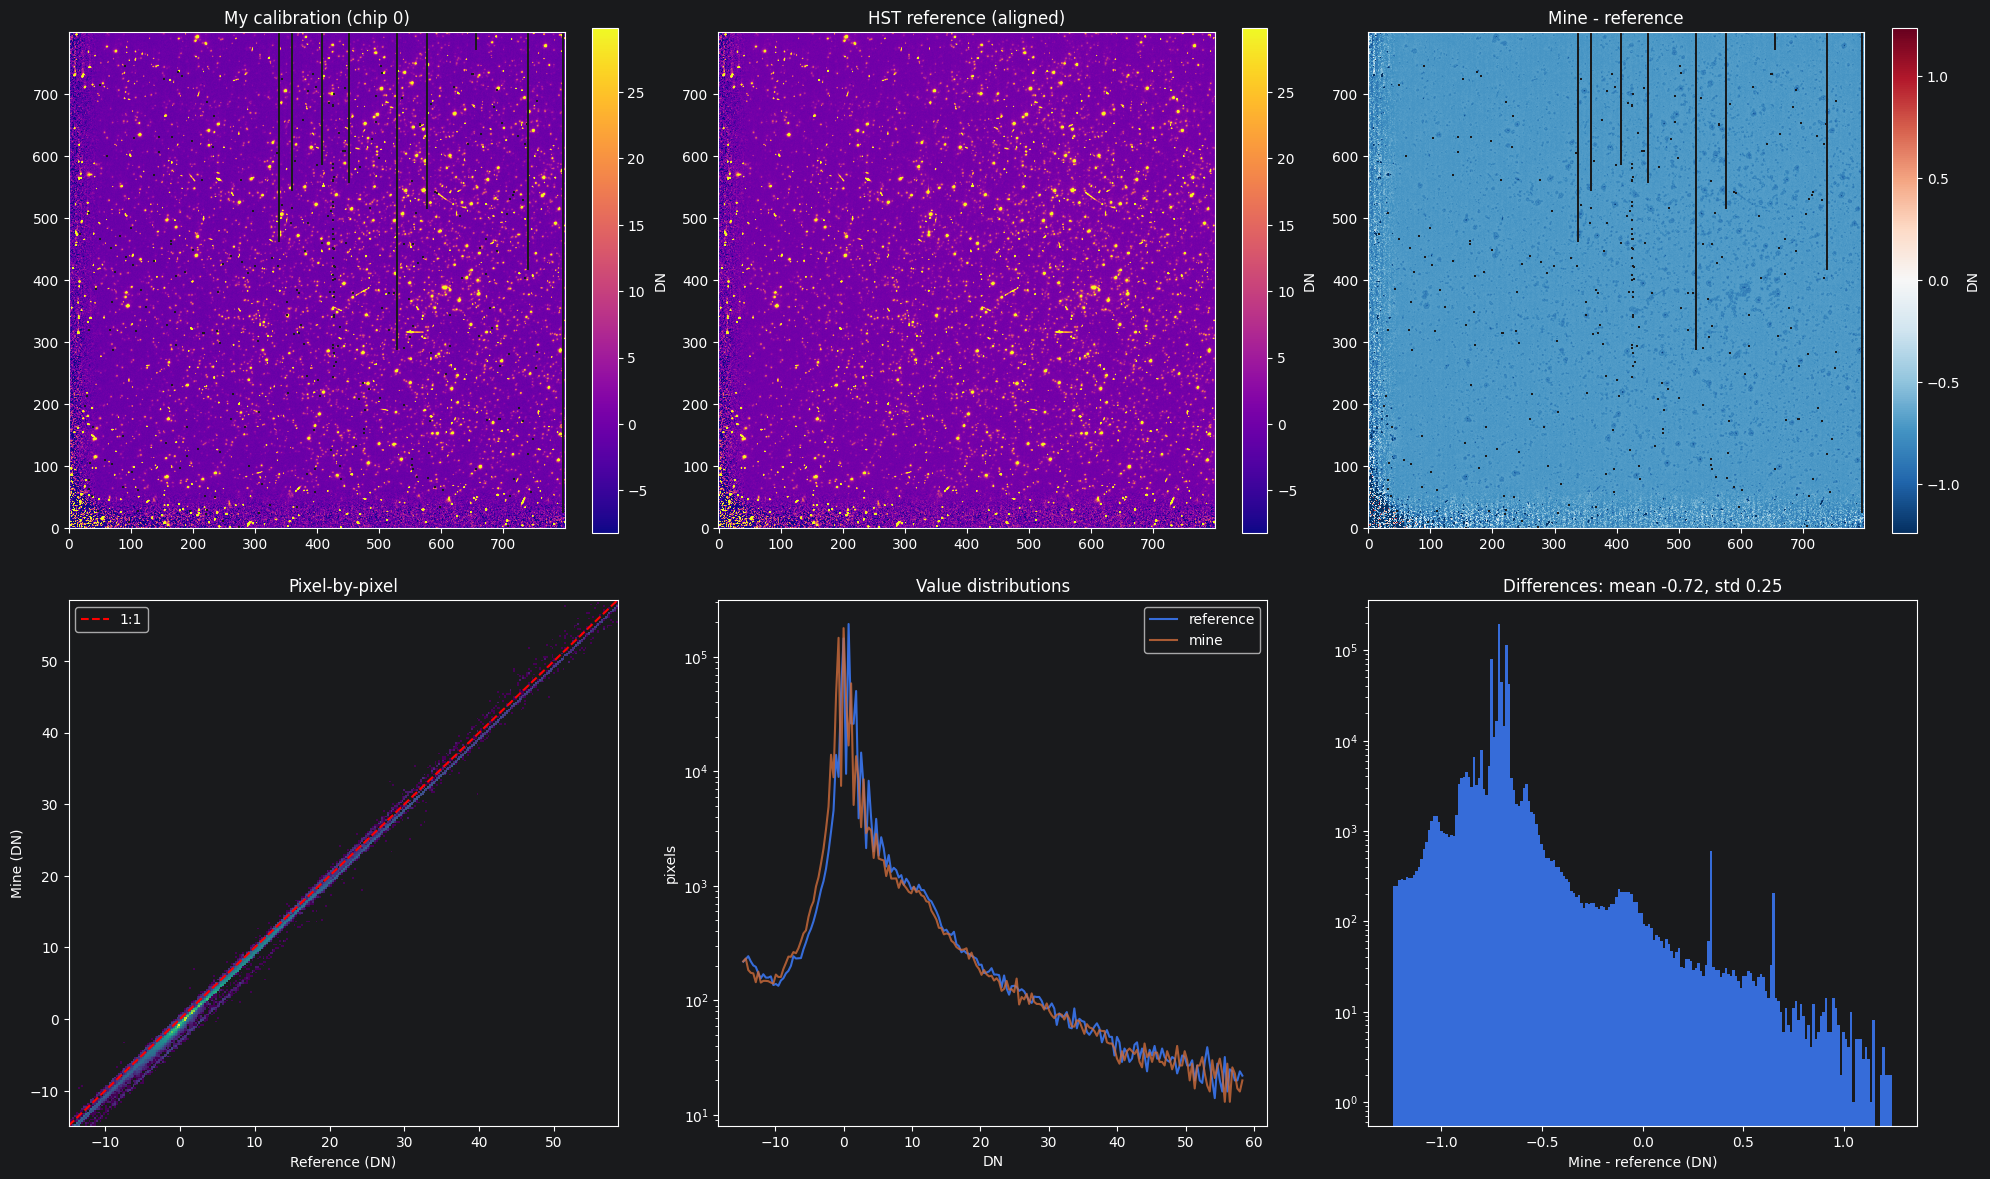

In [669]:
fig = compare_to_reference(sky_corrected, aligned, chip=0)
plt.show()